In [1]:
!pip -q install -U transformers accelerate sentence-transformers faiss-cpu pypdf tiktoken pandas matplotlib seaborn jsonschema

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [2]:
import torch
import os

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1), "GB")

MAIN_MODEL = "Qwen/Qwen3-14B"
JUDGE_MODEL = "Qwen/Qwen3-8B"
EMBED_MODEL = "BAAI/bge-base-en-v1.5"

OUTPUT_DIR = "/content/poland_llm_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.5 GB


Upload & process the PDF

In [3]:
from google.colab import files
from pypdf import PdfReader
import re
import tiktoken
import json
import os

uploaded = files.upload()
pdf_path = next(
    name for name in uploaded
    if name.lower().endswith(".pdf")
)

reader = PdfReader(pdf_path)
pages = []

for page_no, page in enumerate(reader.pages, 1):
    text = page.extract_text() or ""
    text = re.sub(r'\s+', ' ', text).strip()

    if text:
        pages.append({
            "page": page_no,
            "text": text
        })

encoding = tiktoken.get_encoding("cl100k_base")
chunks = []

chunk_size = 450
overlap = 50
step = chunk_size - overlap

for page in pages:
    tokens = encoding.encode(page["text"])

    for start in range(0, len(tokens), step):
        token_chunk = tokens[start:start + chunk_size]

        if not token_chunk:
            continue

        chunks.append({
            "chunk_id": len(chunks),
            "page": page["page"],
            "text": encoding.decode(token_chunk),
            "token_count": len(token_chunk)
        })

with open(f"{OUTPUT_DIR}/chunks.json", "w") as f:
    json.dump(chunks, f, indent=2)

with open(f"{OUTPUT_DIR}/pages.json", "w") as f:
    json.dump(pages, f, indent=2)

print("Total PDF pages:", len(reader.pages))
print("Pages containing text:", len(pages))
print("Total chunks:", len(chunks))
print("Maximum chunk tokens:", max(c["token_count"] for c in chunks))

Saving null-002.2023.issue-189-en.pdf to null-002.2023.issue-189-en.pdf
Total PDF pages: 87
Pages containing text: 86
Total chunks: 182
Maximum chunk tokens: 450


Load Qwen3-14B and test

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MAIN_MODEL)

model = AutoModelForCausalLM.from_pretrained(
    MAIN_MODEL,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    low_cpu_mem_usage=True
)

def ask_llm(prompt, max_tokens=250):
    messages = [
        {
            "role": "system",
            "content": (
                "You are a financial report analyst. "
                "Use only the supplied IMF source text. "
                "Do not invent facts, figures or recommendations. "
                "If evidence is unavailable, state that clearly."
            )
        },
        {"role": "user", "content": prompt}
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=6000
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    response = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return response.strip()

test_prompt = f"""
Summarise the following extract from Poland's
IMF 2023 Article IV report in 60 words or fewer.

Source text:
{chunks[0]['text']}
"""

print(ask_llm(test_prompt, 130))

config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (3 outputs left out)

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/443 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

The IMF's 2023 Article IV consultation with Poland includes a Press Release, Staff Report, and Informational Annex. The Staff Report, completed May 10, 2023, summarizes discussions with Polish officials ending March 24, 2023. The report is available publicly from the IMF.


Inspect the report's section headings

In [5]:

import re

print("POLAND IMF REPORT — SECTION HEADING CANDIDATES\n")

headings = []

for page in pages:
    lines = re.split(r'(?<=[.!?])\s+', page["text"])

    for line in lines:
        line = line.strip()

        if (
            5 <= len(line) <= 110
            and re.search(
                r'(?i)\b(context|recent developments|outlook|risks|'
                r'fiscal|monetary|financial sector|energy|climate|'
                r'labor|labour|staff appraisal|policy discussions)\b',
                line
            )
        ):
            headings.append({
                "page": page["page"],
                "text": line[:110]
            })

for item in headings[:35]:
    print(f"Page {item['page']}: {item['text']}")

POLAND IMF REPORT — SECTION HEADING CANDIDATES

Page 2: © 2023 International Monetary Fund IMF Country Report No.
Page 2: June 2023 ©International Monetary Fund.
Page 3: The central bank tightened monetary policy significantly in 2021-22 before pausing in late 2022.
Page 3: ©International Monetary Fund.
Page 4: Labor markets remain tight, though some signs of cooling have emerged.
Page 4: A fiscal expansion in 2023 should be avoided to help combat still-high inflation.
Page 4: Further energy price measures, if needed, should be temporary, targeted, and preserve price signals.
Page 4: The expected stabilization of food and energy prices should reduce headline inflation in 2023.
Page 4: ©International Monetary Fund.
Page 5: ©International Monetary Fund.
Page 6: ©International Monetary Fund.
Page 7: With Russia’s war in Ukraine, the authorities seek to increase defense expenditures and energy security.
Page 7: Outlook and risks: The economy has slowed considerably, though inflation remain

Identify the main report sections

In [6]:

import re
import json

section_names = [
    "OUTLOOK AND RISKS",
    "FISCAL POLICIES",
    "MONETARY AND EXCHANGE RATE POLICIES",
    "FINANCIAL SECTOR POLICIES",
    "ENERGY AND CLIMATE POLICIES",
    "LABOR MARKETS AND REFUGEES",
    "STAFF APPRAISAL"
]

section_starts = []

for name in section_names:
    matches = []

    for i, page in enumerate(pages):
        if page["page"] <= 10:
            continue

        match = re.search(
            re.escape(name),
            page["text"],
            re.IGNORECASE
        )

        if match:
            matches.append((i, match.start()))

    if matches:
        section_starts.append((matches[0][0], matches[0][1], name))

section_starts.sort()

sections = {}

for idx, (page_idx, char_idx, name) in enumerate(section_starts):

    text_parts = [pages[page_idx]["text"][char_idx:]]

    end_idx = (
        section_starts[idx + 1][0]
        if idx + 1 < len(section_starts)
        else len(pages)
    )

    for j in range(page_idx + 1, end_idx):
        text_parts.append(pages[j]["text"])

    sections[name] = " ".join(text_parts)

with open(f"{OUTPUT_DIR}/sections.json", "w") as f:
    json.dump(sections, f, indent=2)

print("POLAND IMF — EXTRACTED SECTIONS\n")

for name, text in sections.items():
    print(name, "| Characters:", len(text))

POLAND IMF — EXTRACTED SECTIONS

OUTLOOK AND RISKS | Characters: 5872
FISCAL POLICIES | Characters: 14344
MONETARY AND EXCHANGE RATE POLICIES | Characters: 6295
FINANCIAL SECTOR POLICIES | Characters: 13551
ENERGY AND CLIMATE POLICIES | Characters: 5064
LABOR MARKETS AND REFUGEES | Characters: 3083
STAFF APPRAISAL | Characters: 130103


In [7]:
from pypdf import PdfReader
import re
import json

reader = PdfReader(pdf_path)
raw_pages = [
    page.extract_text() or ""
    for page in reader.pages
]

staff_text = sections["STAFF APPRAISAL"]
staff_page = next(
    p["page"] for p in pages
    if "STAFF APPRAISAL" in p["text"].upper()
    and p["page"] > 10
)

# Find the next major annex or statistical-table heading
stops = []

for page_number in range(staff_page, len(raw_pages) + 1):
    raw = raw_pages[page_number - 1]

    for match in re.finditer(
        r"(?im)^\s*(?:ANNEX\s+[IVX0-9]+(?:\s*[:.])?|"
        r"TABLE\s+1\s*[.:]|"
        r"STATISTICAL\s+TABLES|"
        r"INFORMATIONAL\s+ANNEX)\b",
        raw
    ):
        stops.append((page_number, match.group().strip()))

print("Possible section ending headings:")
for item in stops[:8]:
    print(item)

print("\nCurrent Staff Appraisal length:", len(staff_text))

Possible section ending headings:
(48, 'Annex I')
(49, 'Annex II')
(54, 'Annex III')
(55, 'Annex IV')
(56, 'Annex V')
(59, 'Annex VI')
(64, 'Annex VII')
(71, 'Annex VIII')

Current Staff Appraisal length: 130103


In [8]:
# Locate Staff Appraisal in the original PDF text
staff_start = None

for i, raw in enumerate(raw_pages):
    if i < 10:
        continue

    match = re.search(
        r"(?im)^\s*(?:STAFF APPRAISAL)\s*$",
        raw
    )

    if match:
        staff_start = (i, match.end())
        break

if staff_start is None:
    raise ValueError("Staff Appraisal heading not found")

# Collect only the Staff Appraisal text before Annex I
start_page, start_position = staff_start
staff_parts = [raw_pages[start_page][start_position:]]

for i in range(start_page + 1, 47):
    staff_parts.append(raw_pages[i])

staff_clean = re.sub(
    r"\s+", " ", " ".join(staff_parts)
).strip()

sections["STAFF APPRAISAL"] = staff_clean

with open(f"{OUTPUT_DIR}/sections.json", "w") as f:
    json.dump(sections, f, indent=2)

print("CORRECTED SECTIONS\n")

for name, content in sections.items():
    print(name, "| Characters:", len(content))

CORRECTED SECTIONS

OUTLOOK AND RISKS | Characters: 5872
FISCAL POLICIES | Characters: 14344
MONETARY AND EXCHANGE RATE POLICIES | Characters: 6295
FINANCIAL SECTOR POLICIES | Characters: 13551
ENERGY AND CLIMATE POLICIES | Characters: 5064
LABOR MARKETS AND REFUGEES | Characters: 3083
STAFF APPRAISAL | Characters: 34331


In [9]:
# Identify the first table or figure heading after Staff Appraisal
start_page, start_position = staff_start

staff_source = "\n".join(
    [raw_pages[start_page][start_position:]] +
    raw_pages[start_page + 1:47]
)

boundary = re.search(
    r"(?im)^\s*(?:FIGURES|TABLES|"
    r"FIGURE\s+1\s*[.:]|TABLE\s+1\s*[.:])"
    r"(?:\s|$)",
    staff_source
)

if boundary:
    staff_source = staff_source[:boundary.start()]
    print("Statistical appendix boundary detected")
else:
    print("No statistical boundary found; inspect section manually")

sections["STAFF APPRAISAL"] = re.sub(
    r"\s+", " ", staff_source
).strip()

with open(f"{OUTPUT_DIR}/sections.json", "w") as f:
    json.dump(sections, f, indent=2)

print("Staff Appraisal characters:", len(sections["STAFF APPRAISAL"]))
print("Total sections:", len(sections))

No statistical boundary found; inspect section manually
Staff Appraisal characters: 34331
Total sections: 7


seven section summaries using Qwen3-14B

In [10]:
import json
import re

summaries = {}

for section_name, source_text in sections.items():

    prompt = f"""
Summarise this section from the IMF 2023 Poland Article IV report.

Section: {section_name}

Requirements:
- Write 70 to 90 words.
- Use only the provided source text.
- Focus on Poland's economic conditions, policies and risks.
- Include important numerical findings when supported.
- Do not invent information.
- Avoid generic statements and repetition.
- Write one clear academic paragraph.
- Do not include introductory phrases.

SOURCE TEXT:
{source_text}
"""

    summary = ask_llm(prompt, max_tokens=220)
    word_count = len(summary.split())

    if word_count >= 100:
        shorter_prompt = f"""
Rewrite the following summary in fewer than 95 words.
Preserve the economic findings and numerical facts.
Do not add new information.

{summary}
"""
        summary = ask_llm(shorter_prompt, max_tokens=160)
        word_count = len(summary.split())

    summaries[section_name] = {
        "summary": summary,
        "word_count": word_count
    }

    print(f"\n{section_name}")
    print("Words:", word_count)
    print(summary)
    print("-" * 60)

with open(f"{OUTPUT_DIR}/section_summaries.json", "w") as f:
    json.dump(summaries, f, indent=2)

print("\nSummaries saved successfully")
print("Under 100 words:",
      all(s["word_count"] < 100 for s in summaries.values()))


OUTLOOK AND RISKS
Words: 96
Poland's 2023 growth is projected at 0.3%, with recession risks from high energy prices, monetary tightening, and weak Euro Area demand. Private consumption declines as inflation erodes real wages, while investment faces headwinds. Growth is expected to rebound to 2.4% in 2024 as real wages recover. Medium-term growth is forecast above 3%, supported by NGEU funds, which could raise output by 1% by 2025. The current account deficit is expected to narrow to 2% of GDP, though EU funding and military spending will keep it in deficit. Risks include war escalation, banking turmoil, and slower-than-expected inflation.
------------------------------------------------------------

FISCAL POLICIES
Words: 88
Poland's fiscal deficit is expected to reach 4.5% of GDP in 2023 due to a slowing economy, higher interest payments, and the "Polish Deal" PIT reforms. The "Energy Shield" costs 1.9% of GDP, partially offset by 0.9% from energy taxes. Defense spending will rise. T

In [11]:

import re
import json

# Recover numbered Staff Appraisal paragraphs from the PDF
start_page, start_position = staff_start

source = "\n".join(
    [raw_pages[start_page][start_position:]] +
    raw_pages[start_page + 1:47]
)

pattern = re.compile(r"(?m)^\s*(\d{1,2})\.\s+(?=[A-Z])")
matches = list(pattern.finditer(source))

paragraphs = []
expected = 38

for i, match in enumerate(matches):
    number = int(match.group(1))

    if number != expected:
        if paragraphs:
            break
        continue

    end = matches[i + 1].start() if i + 1 < len(matches) else len(source)
    paragraph = source[match.end():end]

    # Stop before statistical material
    paragraph = re.split(
        r"(?im)^\s*(?:Table|Figure|Annex)\s+\d+\b",
        paragraph
    )[0]

    paragraphs.append(f"{number}. {paragraph.strip()}")
    expected += 1

if len(paragraphs) < 3:
    raise ValueError("Staff Appraisal paragraphs require inspection")

staff_clean = re.sub(r"\s+", " ", " ".join(paragraphs)).strip()
sections["STAFF APPRAISAL"] = staff_clean

print("Staff paragraphs identified:", len(paragraphs))
print("Staff source characters:", len(staff_clean))

# Regenerate the three problematic summaries
repair_sections = [
    "FINANCIAL SECTOR POLICIES",
    "ENERGY AND CLIMATE POLICIES",
    "STAFF APPRAISAL"
]

for name in repair_sections:
    prompt = f"""
Summarise the following IMF Poland 2023 section.

Section: {name}

Instructions:
- Write one coherent paragraph of 65 to 85 words.
- Focus on key economic findings and policy implications.
- Use only the provided source.
- Do not invent statistics.
- Avoid tables, raw numerical sequences and repetition.
- Do not include a heading.

SOURCE:
{sections[name][:18000]}
"""

    summary = ask_llm(prompt, max_tokens=180)

    for attempt in range(2):
        if len(summary.split()) < 100:
            break

        summary = ask_llm(
            "Rewrite this in 70 to 85 words, preserving "
            "the factual economic findings:\n" + summary,
            max_tokens=150
        )

    summaries[name] = {
        "summary": summary,
        "word_count": len(summary.split())
    }

# Save corrected files
with open(f"{OUTPUT_DIR}/sections.json", "w") as f:
    json.dump(sections, f, indent=2)

with open(f"{OUTPUT_DIR}/section_summaries.json", "w") as f:
    json.dump(summaries, f, indent=2)

print("\nFINAL SECTION SUMMARIES\n")

for name, result in summaries.items():
    print(name)
    print("Words:", result["word_count"])
    print(result["summary"])
    print("-" * 55)

print("Under 100 words:",
      all(s["word_count"] < 100 for s in summaries.values()))

Staff paragraphs identified: 7
Staff source characters: 4606

FINAL SECTION SUMMARIES

OUTLOOK AND RISKS
Words: 96
Poland's 2023 growth is projected at 0.3%, with recession risks from high energy prices, monetary tightening, and weak Euro Area demand. Private consumption declines as inflation erodes real wages, while investment faces headwinds. Growth is expected to rebound to 2.4% in 2024 as real wages recover. Medium-term growth is forecast above 3%, supported by NGEU funds, which could raise output by 1% by 2025. The current account deficit is expected to narrow to 2% of GDP, though EU funding and military spending will keep it in deficit. Risks include war escalation, banking turmoil, and slower-than-expected inflation.
-------------------------------------------------------
FISCAL POLICIES
Words: 88
Poland's fiscal deficit is expected to reach 4.5% of GDP in 2023 due to a slowing economy, higher interest payments, and the "Polish Deal" PIT reforms. The "Energy Shield" costs 1.9% o

Executive summary

In [12]:

import json

combined_summaries = "\n\n".join(
    f"{name}:\n{data['summary']}"
    for name, data in summaries.items()
)

prompt = f"""
You are preparing an executive financial stability summary
of Poland's IMF 2023 Article IV Consultation.

Using only the section summaries below, write exactly
six concise bullet points covering:

1. Economic growth and outlook
2. Inflation and monetary policy
3. Fiscal conditions and public debt
4. Banking sector stability
5. Structural and energy challenges
6. Major macroeconomic and financial risks

Requirements:
- Each bullet should contain 1-2 sentences.
- Include important numerical findings where supported.
- Clearly distinguish forecasts from historical observations.
- Do not introduce unsupported facts.
- Avoid repeating information.
- Use professional financial analysis language.

SOURCE SUMMARIES:
{combined_summaries}
"""

executive_summary = ask_llm(prompt, max_tokens=450)

with open(f"{OUTPUT_DIR}/executive_summary.json", "w") as f:
    json.dump(
        {
            "country": "Poland",
            "report_year": 2023,
            "executive_summary": executive_summary
        },
        f,
        indent=2
    )

print("POLAND IMF 2023 — EXECUTIVE SUMMARY\n")
print(executive_summary)

POLAND IMF 2023 — EXECUTIVE SUMMARY

- **Economic growth and outlook**: Poland's 2023 growth is projected at 0.3%, with recession risks from high energy prices and weak Euro Area demand, though a rebound to 2.4% is expected in 2024 as real wages recover. Medium-term growth is forecast above 3%, supported by NGEU funds.

- **Inflation and monetary policy**: Headline inflation averaged 12.4% in 2023, with a projected decline to 5.1% by end-2024 and 3.6% by end-2025. The NBP has raised its policy rate to 6.75%, with further tightening potentially required to meet the 2.5% medium-term inflation target.

- **Fiscal conditions and public debt**: The fiscal deficit is expected to reach 4.5% of GDP in 2023, with public debt stable at 50% of GDP. Medium-term deficit is projected at 3.5%, with debt rising to 55%, necessitating fiscal adjustments such as VAT increases and pension reforms.

- **Banking sector stability**: Poland’s banking sector remains well capitalized with a total capital ratio 

Extract the seven financial themes

In [13]:
import re
import json
import pandas as pd

financial_themes = {
    "Inflation & Prices": [
        "inflation", "consumer prices", "cpi",
        "price pressures", "disinflation"
    ],
    "Interest Rates & Credit": [
        "interest rate", "policy rate", "lending",
        "credit growth", "monetary tightening"
    ],
    "Housing & Real Estate": [
        "housing", "mortgage", "real estate",
        "property market", "residential property"
    ],
    "Banking Capital & Liquidity": [
        "bank capital", "capital adequacy", "liquidity",
        "capital ratio", "mrel", "banking sector"
    ],
    "Sovereign Debt": [
        "public debt", "government debt", "fiscal deficit",
        "debt sustainability", "sovereign debt"
    ],
    "Labor Market Dynamics": [
        "employment", "unemployment", "labor market",
        "labour market", "wages", "refugees"
    ],
    "Systemic Financial Risk": [
        "financial stability", "systemic risk",
        "financial risks", "financial vulnerabilities",
        "banking risks", "fx mortgage"
    ]
}

# Use extracted IMF text, excluding front matter
report_text = " ".join(
    page["text"] for page in pages
    if page["page"] >= 11
)

theme_results = []

for theme, keywords in financial_themes.items():
    count = 0

    for keyword in keywords:
        pattern = r"\b" + re.escape(keyword) + r"\b"
        count += len(re.findall(pattern, report_text, re.I))

    theme_results.append({
        "theme": theme,
        "count": count
    })

theme_df = pd.DataFrame(theme_results)
total = theme_df["count"].sum()

theme_df["percentage"] = (
    theme_df["count"] / total * 100
).round(2) if total else 0.0

theme_df = theme_df.sort_values(
    "count", ascending=False
).reset_index(drop=True)

theme_df.to_json(
    f"{OUTPUT_DIR}/financial_themes.json",
    orient="records",
    indent=2
)

theme_df.to_csv(
    f"{OUTPUT_DIR}/financial_themes.csv",
    index=False
)

print("POLAND IMF 2023 — FINANCIAL THEMES\n")
print(theme_df.to_string(index=False))
print("\nTotal keyword matches:", total)
print("Themes identified:", len(theme_df))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


POLAND IMF 2023 — FINANCIAL THEMES

                      theme  count  percentage
         Inflation & Prices    155       31.76
      Labor Market Dynamics    119       24.39
    Interest Rates & Credit     71       14.55
             Sovereign Debt     46        9.43
Banking Capital & Liquidity     45        9.22
      Housing & Real Estate     39        7.99
    Systemic Financial Risk     13        2.66

Total keyword matches: 488
Themes identified: 7


Financial indicator extraction using Qwen3-14B

In [14]:

import json
import re
import os
import pandas as pd

indicator_queries = {
    "gdp_growth_forecast_pct":
        ["GDP growth", "real GDP growth", "growth projected"],
    "headline_inflation_rate_pct":
        ["average inflation", "headline inflation", "CPI inflation"],
    "central_bank_policy_rate_pct":
        ["policy rate", "reference rate", "6.75"],
    "non_performing_loan_ratio":
        ["non-performing loans", "NPL ratio", "nonperforming loans"],
    "unemployment_rate_pct":
        ["unemployment rate", "unemployment"],
    "tier_1_capital_ratio":
        ["Tier 1 capital", "Tier-1 capital", "CET1"]
}

def find_evidence(keywords, top_k=5):
    ranked = []

    for chunk in chunks:
        content = chunk["text"].lower()
        score = sum(
            content.count(term.lower())
            for term in keywords
        )

        if score:
            ranked.append((score, chunk))

    ranked.sort(key=lambda x: x[0], reverse=True)
    return [item[1] for item in ranked[:top_k]]

financial_json = {"country_name": "Poland"}
financial_audit = {}

for indicator, keywords in indicator_queries.items():

    evidence = find_evidence(keywords)

    context = "\n\n".join(
        f"[PDF page {c['page']}]\n{c['text']}"
        for c in evidence
    )

    prompt = f"""
Extract ONE financial indicator from Poland's IMF 2023
Article IV Consultation report.

Indicator: {indicator}

Return ONLY a valid JSON object with:
"value": numeric percentage or null
"page": PDF page number or null
"year": observation or forecast year, or null
"evidence": short exact supporting quotation
"status": "extracted" or "missing"

Rules:
- Use only the source text below.
- Select the value most relevant to this indicator.
- GDP growth must refer to the 2023 forecast.
- Headline inflation must refer to the 2023 annual forecast.
- For other indicators, prefer the latest clearly dated
  observation available in the supplied passages.
- Do not confuse total capital with Tier 1 capital.
- Do not confuse policy rates with market interest rates.
- Never invent a number.
- Return null when the evidence is insufficient.
- Do not include markdown.

SOURCE:
{context}
"""

    response = ask_llm(prompt, max_tokens=250)

    try:
        match = re.search(r'\{.*\}', response, re.S)
        if not match:
            raise ValueError("No JSON object")

        result = json.loads(match.group())

        value = result.get("value")
        page = result.get("page")
        quote = result.get("evidence", "")

        # Only accept numeric values with a traceable
        # page and an exact source quotation.
        evidence_pages = {c["page"] for c in evidence}

        quoted_in_source = (
            isinstance(quote, str)
            and any(
                quote.strip().lower() in c["text"].lower()
                for c in evidence
                if c["page"] == page
            )
        )

        valid = (
            isinstance(value, (int, float))
            and not isinstance(value, bool)
            and page in evidence_pages
            and quoted_in_source
            and any(
                re.search(
                    rf'(?<!\d){re.escape(str(value))}(?!\d)',
                    quote
                )
                for _ in [0]
            )
        )

        financial_json[indicator] = float(value) if valid else None

        financial_audit[indicator] = {
            "value": financial_json[indicator],
            "page": page if valid else None,
            "year": result.get("year") if valid else None,
            "evidence": quote if valid else None,
            "status": "requires_source_review" if valid else "missing_unverified"
        }

    except (ValueError, TypeError, json.JSONDecodeError):
        financial_json[indicator] = None
        financial_audit[indicator] = {
            "value": None,
            "page": None,
            "year": None,
            "evidence": None,
            "status": "missing_unverified"
        }

with open(f"{OUTPUT_DIR}/financial_indicators.json", "w") as f:
    json.dump(financial_json, f, indent=2)

with open(f"{OUTPUT_DIR}/financial_source_audit.json", "w") as f:
    json.dump(financial_audit, f, indent=2)

print("POLAND — FINANCIAL INDICATORS\n")
print(json.dumps(financial_json, indent=2))

print("\nSOURCE EVIDENCE\n")
for name, audit in financial_audit.items():
    print(name)
    print("Page:", audit["page"])
    print("Year:", audit["year"])
    print("Status:", audit["status"])
    print("Evidence:", audit["evidence"])
    print("-" * 50)

POLAND — FINANCIAL INDICATORS

{
  "country_name": "Poland",
  "gdp_growth_forecast_pct": 0.3,
  "headline_inflation_rate_pct": 12.4,
  "central_bank_policy_rate_pct": 6.75,
  "non_performing_loan_ratio": null,
  "unemployment_rate_pct": 3.2,
  "tier_1_capital_ratio": null
}

SOURCE EVIDENCE

gdp_growth_forecast_pct
Page: 22
Year: 2023
Status: requires_source_review
Evidence: Real GDP growth (percent) Baseline 0.3 2.4 3.7 3.4 3.1 3.1
--------------------------------------------------
headline_inflation_rate_pct
Page: 24
Year: 2023
Status: requires_source_review
Evidence: Headline inflation is projected to average 12.4 percent in 2023, before slowing to 5.1 percent at end-2024 and 3.6 percent by end-2025 (Figure 10).
--------------------------------------------------
central_bank_policy_rate_pct
Page: 56
Year: None
Status: requires_source_review
Evidence: the policy interest rate, currently held at 6.75 percent
--------------------------------------------------
non_performing_loan_ratio

In [15]:

import re

search_terms = {
    "Non-performing loan ratio": [
        r"non.performing loans?",
        r"\bNPLs?\b",
        r"impaired loans?",
        r"asset quality",
        r"nonperforming"
    ],
    "Tier 1 capital ratio": [
        r"tier[\s-]*1",
        r"\bCET1\b",
        r"common equity tier",
        r"capital adequacy",
        r"regulatory capital",
        r"risk.weighted assets"
    ]
}

for indicator, patterns in search_terms.items():
    print(f"\n{'=' * 55}")
    print(indicator.upper())
    print("=" * 55)

    matches = []

    for page in pages:
        text = page["text"]

        for pattern in patterns:
            for match in re.finditer(pattern, text, re.I):
                start = max(0, match.start() - 180)
                end = min(len(text), match.end() + 300)

                snippet = text[start:end]
                snippet = re.sub(r"\s+", " ", snippet)

                matches.append({
                    "page": page["page"],
                    "term": match.group(),
                    "context": snippet
                })

    print("Total matches:", len(matches))

    # Show useful evidence from distinct pages
    shown_pages = set()

    for item in matches:
        if item["page"] in shown_pages:
            continue

        print(f"\nPDF Page {item['page']}")
        print(item["context"])
        print("-" * 45)

        shown_pages.add(item["page"])

        if len(shown_pages) >= 12:
            break


NON-PERFORMING LOAN RATIO
Total matches: 6

PDF Page 3
e in headline inflation in 2023, though the easing of core inflation is projected to be more protracted. Inflation is projected to decline near the target by the end of 2025. Bank asset quality has remained stable, and sector-wide capital adequacy levels remain significantly above regulatory requirements. Supported by rising lending interest rates, banks remained profitable in 2022, despite the cost of mortgage credit holidays. The legal risks stemming from foreign-currency denominated mo
---------------------------------------------

PDF Page 4
 intervention should continue to be reserved for disorderly market conditions. While the banking sector has remained stable, there are significant legal and regulatory challenges. Asset quality has not deteriorated, and sector-wide capital adequacy levels remain significantly above regulatory requirements. However, ongoing challenges reduce banks’ profitability and could limit their abilit

Complete financial JSON extraction

In [16]:
import re
import json

source_page = next(
    p["text"] for p in pages
    if p["page"] == 47
)

indicators_to_extract = {
    "non_performing_loan_ratio":
        r"NPLs to gross loans\s*\(nonfinancial sector\)",
    "tier_1_capital_ratio":
        r"Regulatory Tier I capital to risk-weighted assets"
}

for indicator, label_pattern in indicators_to_extract.items():

    match = re.search(label_pattern, source_page, re.I)

    if not match:
        print(indicator, "— source row not found")
        continue

    row_text = source_page[match.end():]

    # Capture the eight annual observations, 2015–2022
    values = re.findall(
        r"(?<!\d)\d{1,2}\.\d+(?!\d)",
        row_text
    )[:8]

    if len(values) != 8:
        print(indicator, "— unexpected number of values")
        continue

    value = float(values[-1])

    financial_json[indicator] = value

    financial_audit[indicator] = {
        "value": value,
        "page": 47,
        "year": 2022,
        "evidence": match.group() + " " + " ".join(values),
        "status": "source_table_extracted_pending_review"
    }

with open(f"{OUTPUT_DIR}/financial_indicators.json", "w") as f:
    json.dump(financial_json, f, indent=2)

with open(f"{OUTPUT_DIR}/financial_source_audit.json", "w") as f:
    json.dump(financial_audit, f, indent=2)

print("UPDATED FINANCIAL INDICATORS\n")
print(json.dumps(financial_json, indent=2))

print("\nSOURCE AUDIT\n")
for indicator, detail in financial_audit.items():
    print(
        indicator,
        "|", detail["value"],
        "| PDF page:", detail["page"],
        "|", detail["status"]
    )

print("\nNumeric indicators extracted:",
      sum(
          isinstance(financial_json[k], (int, float))
          for k in indicators_to_extract.keys()
      ), "/ 2")

UPDATED FINANCIAL INDICATORS

{
  "country_name": "Poland",
  "gdp_growth_forecast_pct": 0.3,
  "headline_inflation_rate_pct": 12.4,
  "central_bank_policy_rate_pct": 6.75,
  "non_performing_loan_ratio": 2.6,
  "unemployment_rate_pct": 3.2,
  "tier_1_capital_ratio": 15.2
}

SOURCE AUDIT

gdp_growth_forecast_pct | 0.3 | PDF page: 22 | requires_source_review
headline_inflation_rate_pct | 12.4 | PDF page: 24 | requires_source_review
central_bank_policy_rate_pct | 6.75 | PDF page: 56 | requires_source_review
non_performing_loan_ratio | 2.6 | PDF page: 47 | source_table_extracted_pending_review
unemployment_rate_pct | 3.2 | PDF page: 6 | requires_source_review
tier_1_capital_ratio | 15.2 | PDF page: 47 | source_table_extracted_pending_review

Numeric indicators extracted: 2 / 2


Economic strengths and vulnerabilities

In [17]:
import json
import re

# Use relevant report sections as source evidence
selected_sections = [
    "OUTLOOK AND RISKS",
    "FISCAL POLICIES",
    "MONETARY AND EXCHANGE RATE POLICIES",
    "FINANCIAL SECTOR POLICIES",
    "ENERGY AND CLIMATE POLICIES",
    "LABOR MARKETS AND REFUGEES"
]

context = "\n\n".join(
    f"{name}:\n{sections[name][:3500]}"
    for name in selected_sections
)

prompt = f"""
Analyse Poland's economic and financial stability
using the IMF 2023 Article IV report excerpts below.

Extract exactly:
- 6 economic strengths or growth drivers
- 6 economic vulnerabilities or challenges

Return ONLY valid JSON with this structure:

{{
  "country": "Poland",
  "strengths": [
    "strength 1",
    "strength 2"
  ],
  "vulnerabilities": [
    "vulnerability 1",
    "vulnerability 2"
  ]
}}

Rules:
- Each item must be one clear sentence.
- Use only information supported by the source.
- Include economic implications where appropriate.
- Do not invent facts or statistics.
- Do not repeat the same finding.
- Avoid vague statements.
- Return exactly 6 items in each category.

SOURCE:
{context}
"""

response = ask_llm(prompt, max_tokens=650)

try:
    match = re.search(r"\{.*\}", response, re.S)

    if not match:
        raise ValueError("No JSON found")

    insights = json.loads(match.group())

    strengths = insights.get("strengths", [])
    vulnerabilities = insights.get("vulnerabilities", [])

    if not (
        isinstance(strengths, list)
        and isinstance(vulnerabilities, list)
        and len(strengths) == 6
        and len(vulnerabilities) == 6
        and all(isinstance(x, str) and x.strip()
                for x in strengths + vulnerabilities)
    ):
        raise ValueError("Invalid insight structure")

except (ValueError, json.JSONDecodeError) as e:
    raise ValueError(
        "Insight extraction failed. Review model response."
    ) from e

with open(f"{OUTPUT_DIR}/qualitative_insights.json", "w") as f:
    json.dump(insights, f, indent=2)

print("POLAND — ECONOMIC STRENGTHS\n")

for i, item in enumerate(strengths, 1):
    print(f"{i}. {item}")

print("\nPOLAND — ECONOMIC VULNERABILITIES\n")

for i, item in enumerate(vulnerabilities, 1):
    print(f"{i}. {item}")

print("\nStrengths:", len(strengths))
print("Vulnerabilities:", len(vulnerabilities))

POLAND — ECONOMIC STRENGTHS

1. Poland's medium-term economic growth is projected to exceed 3 percent, supported by strong investment and Next Generation EU (NGEU) funding.
2. The labor market remains tight, with a significant portion of Ukrainian refugees successfully integrated into the workforce, contributing to economic activity.
3. The Polish Development Fund (PFR) is pre-financing Next Generation EU-related investments, which will support infrastructure and economic development over 2024-26.
4. The banking sector remains well capitalized, with a total capital ratio of 19.5 percent in 2022, providing stability to the financial system.
5. The government has implemented policies to support energy security, including a focus on renewable energy and nuclear power, which could reduce long-term energy import dependency.
6. The economy is projected to recover in the second half of 2023 and grow at 2.4 percent in 2024 as real wage growth recovers and shocks fade.

POLAND — ECONOMIC VULNER

Locate economic trend tables

In [18]:

import re

trend_patterns = {
    "Real GDP Growth": [
        r"real GDP growth",
        r"real GDP\s*\(percent change\)"
    ],
    "Inflation": [
        r"consumer prices",
        r"headline inflation",
        r"inflation\s*\(percent"
    ],
    "Government Debt": [
        r"general government debt",
        r"public debt",
        r"gross debt"
    ],
    "Current Account Balance": [
        r"current account balance",
        r"current account\s*\(percent"
    ]
}

trend_candidates = {}

for trend, patterns in trend_patterns.items():
    candidates = []

    for page in pages:
        if page["page"] < 38 or page["page"] > 48:
            continue

        for pattern in patterns:
            match = re.search(pattern, page["text"], re.I)

            if match:
                start = max(0, match.start() - 180)
                end = min(len(page["text"]), match.end() + 350)

                candidates.append({
                    "page": page["page"],
                    "evidence": page["text"][start:end]
                })
                break

    trend_candidates[trend] = candidates

print("POLAND IMF — ECONOMIC TREND SOURCE SEARCH\n")

for trend, candidates in trend_candidates.items():
    print("\n", trend.upper())

    if not candidates:
        print("No table evidence found in selected pages.")
        continue

    for item in candidates[:3]:
        print("PDF page:", item["page"])
        print(item["evidence"])
        print("-" * 45)

POLAND IMF — ECONOMIC TREND SOURCE SEARCH


 REAL GDP GROWTH
No table evidence found in selected pages.

 INFLATION
PDF page: 40
0 15 20 2011 2013 2015 2017 2019 2021 2023 Consumer Price Inflation (Percentage point contribution to overall yoy inflation) Electricity, gas, other fuels Fuel Food Core inflation Headline inflation 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 2 0 1 12 0 1 32 0 1 52 0 1 72 0 1 92 0 2 12 0 2 3 Inflation Expectations, One Year Ahead (Year-on-year inflation in percent) Consensus forecast (following year-average 1/) Survey of professional forecasters 0 1 2 3 4 5 6 7 8 2011 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 Interest Rates (In perce
---------------------------------------------
PDF page: 43
6 -0.4 -0.6 -0.7 -0.3 -0.2 -0.1 Net external demand (contribution to growth) 0.7 -1.3 0.1 1.4 0.3 0.0 0.1 0.0 0.0 Output gap -2.7 0.6 2.2 -0.6 -1.3 -0.6 -0.2 -0.1 0.0 Headline CPI inflation (percent) Average 3.4 5.1 14.4 12.4 6.2 4.2 3.5 2.9 2.5 End of period 2.4

In [19]:

import re

table_page = next(
    p["text"] for p in pages
    if p["page"] == 43
)

print("POLAND IMF — ECONOMIC INDICATOR TABLE\n")

# Display table heading and year labels
print("TABLE HEADER:")
print(table_page[:1800])

print("\n" + "=" * 60)
print("GDP GROWTH ROW CANDIDATES\n")

gdp_patterns = [
    r"real GDP",
    r"GDP growth",
    r"gross domestic product",
    r"real GDP.*?percent"
]

for pattern in gdp_patterns:
    for match in list(
        re.finditer(pattern, table_page, re.I)
    )[:3]:

        start = max(0, match.start() - 120)
        end = min(len(table_page), match.end() + 350)

        print(table_page[start:end])
        print("-" * 50)

POLAND IMF — ECONOMIC INDICATOR TABLE

TABLE HEADER:
REPUBLIC OF POLAND INTERNATIONAL MONETARY FUND 37 Table 5. Poland: Selected Economic Indicators, 2020-2028 2020 2021 2022 2023 2024 2025 2026 2027 2028 Activity and prices GDP (change in percent) -2.0 6.9 5.1 0.3 2.4 3.7 3.4 3.1 3.1 Domestic demand -2.8 8.6 5.1 -1.1 2.2 3.9 3.5 3.2 3.2 Private consumption growth -3.4 6.1 3.3 -1.2 2.5 4.2 3.6 3.5 3.5 Public consumption growth 4.9 5.0 -2.0 -2.1 4.1 3.8 3.5 3.1 3.1 Domestic fixed investment growth -2.3 1.2 5.0 2.2 3.3 8.0 5.5 4.0 3.5 Inventories (contribution to growth) -1.1 3.6 2.6 -0.4 -0.6 -0.7 -0.3 -0.2 -0.1 Net external demand (contribution to growth) 0.7 -1.3 0.1 1.4 0.3 0.0 0.1 0.0 0.0 Output gap -2.7 0.6 2.2 -0.6 -1.3 -0.6 -0.2 -0.1 0.0 Headline CPI inflation (percent) Average 3.4 5.1 14.4 12.4 6.2 4.2 3.5 2.9 2.5 End of period 2.4 8.6 16.6 7.7 5.1 3.6 3.3 2.5 2.5 CPI inflation excluding food and energy (percent) Average 3.9 4.1 9.1 11.2 7.7 5.0 3.6 2.9 2.5 End of period 3.7 5.3

In [20]:

import re
import json
import pandas as pd

table_text = table_page
years = list(range(2020, 2029))
number = r"-?\d+(?:\.\d+)?"

# Check that the table contains the correct years
year_header = " ".join(str(y) for y in years)
assert year_header in table_text, "Unexpected table years"

def extract_trend(label, start_at=0):
    match = re.search(label, table_text[start_at:], re.I)

    if not match:
        raise ValueError(f"Source row not found: {label}")

    position = start_at + match.end()
    remainder = table_text[position:]

    # Read exactly nine consecutive annual values
    row = re.match(
        rf"\s*((?:{number}\s+){{8}}{number})",
        remainder
    )

    if not row:
        raise ValueError(f"Invalid annual values: {label}")

    values = [float(v) for v in re.findall(number, row.group(1))]

    if len(values) != len(years):
        raise ValueError("Year/value mismatch")

    return values

# Read the indicator rows directly from Table 5
gdp = extract_trend(r"GDP \(change in percent\)")

inflation = extract_trend(
    r"Headline CPI inflation \(percent\)\s*Average"
)

debt = extract_trend(r"General government debt")

# Locate the balance-of-payments subsection
bop_start = table_text.index("Balance of payments")

current_account = extract_trend(
    r"Current account balance \(billion U\.S\. dollars\)"
    rf"\s*(?:{number}\s+){{8}}{number}\s*"
    r"Percent of GDP",
    start_at=bop_start
)

trend_data = {
    "year": years,
    "GDP Growth (%)": gdp,
    "Average Inflation (%)": inflation,
    "Government Debt (% GDP)": debt,
    "Current Account (% GDP)": current_account
}

trend_df = pd.DataFrame(trend_data)

trend_df["period"] = trend_df["year"].apply(
    lambda y: "Historical" if y <= 2022 else "IMF Projection"
)

trend_long = trend_df.melt(
    id_vars=["year", "period"],
    var_name="indicator",
    value_name="value"
)

trend_long["source_pdf_page"] = 43

trend_df.to_csv(
    f"{OUTPUT_DIR}/economic_trends.csv",
    index=False
)

trend_long.to_csv(
    f"{OUTPUT_DIR}/economic_trends_long.csv",
    index=False
)

trend_long.to_json(
    f"{OUTPUT_DIR}/economic_trends.json",
    orient="records",
    indent=2
)

print("POLAND IMF 2023 — ECONOMIC TRENDS\n")
print(trend_df.to_string(index=False))

print("\nTrend series:", 4)
print("Years:", len(years))
print("Total observations:", len(trend_long))
print("Missing values:", trend_long["value"].isna().sum())

POLAND IMF 2023 — ECONOMIC TRENDS

 year  GDP Growth (%)  Average Inflation (%)  Government Debt (% GDP)  Current Account (% GDP)         period
 2020            -2.0                    3.4                     57.2                      2.5     Historical
 2021             6.9                    5.1                     53.6                     -1.4     Historical
 2022             5.1                   14.4                     49.1                     -3.0     Historical
 2023             0.3                   12.4                     50.2                     -2.4 IMF Projection
 2024             2.4                    6.2                     51.5                     -2.1 IMF Projection
 2025             3.7                    4.2                     52.4                     -2.0 IMF Projection
 2026             3.4                    3.5                     53.7                     -2.0 IMF Projection
 2027             3.1                    2.9                     54.4                

Create and cache the FAISS index

In [21]:

import os
import json
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

index_path = f"{OUTPUT_DIR}/poland_faiss.index"
metadata_path = f"{OUTPUT_DIR}/rag_metadata.json"

embedding_model = SentenceTransformer(
    EMBED_MODEL,
    device="cpu"
)

if os.path.exists(index_path) and os.path.exists(metadata_path):

    index = faiss.read_index(index_path)

    with open(metadata_path) as f:
        rag_chunks = json.load(f)

    if index.ntotal != len(chunks) or len(rag_chunks) != len(chunks):
        raise ValueError("Cached index does not match current chunks")

    print("Cached FAISS index loaded")

else:
    texts = [chunk["text"] for chunk in chunks]

    embeddings = embedding_model.encode(
        texts,
        batch_size=32,
        normalize_embeddings=True,
        show_progress_bar=True
    )

    embeddings = np.asarray(
        embeddings, dtype="float32"
    )

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    rag_chunks = chunks

    faiss.write_index(index, index_path)

    with open(metadata_path, "w") as f:
        json.dump(rag_chunks, f, indent=2)

    print("New FAISS index created and cached")

print("Indexed chunks:", index.ntotal)
print("Embedding dimensions:", index.d)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

New FAISS index created and cached
Indexed chunks: 182
Embedding dimensions: 768


In [22]:

def retrieve_context(question, top_k=4):

    query_embedding = embedding_model.encode(
        [question],
        normalize_embeddings=True
    ).astype("float32")

    scores, ids = index.search(query_embedding, top_k)

    results = []

    for score, idx in zip(scores[0], ids[0]):
        if idx < 0:
            continue

        chunk = rag_chunks[int(idx)]

        results.append({
            "page": chunk["page"],
            "score": round(float(score), 4),
            "text": chunk["text"]
        })

    return results


question = "What are the main financial stability risks facing Poland?"

retrieved = retrieve_context(question)

print("QUESTION:", question)

for result in retrieved:
    print("\nPDF Page:", result["page"])
    print("Similarity:", result["score"])
    print("Context:", result["text"][:500])
    print("-" * 50)

QUESTION: What are the main financial stability risks facing Poland?

PDF Page: 64
Similarity: 0.7492
Context: REPUBLIC OF POLAND 58 INTERNATIONAL MONETARY FUND Annex VII. Public Sector Debt Sustainability Analysis Table 1: Poland: Risk of Sovereign Stress Overall … Low Near-term 1/ Medium-term Moderate Moderate Fanchart Moderate … GFN Moderate … Stress test … Long-term … Moderate Debt stabilization in the baseline Horizon Mechanical signal Final assessment Comments The overall risk of sovereign stress is low, reflecting the authorities’ capacity to adopt measures that would address factors leading to mo
--------------------------------------------------

PDF Page: 17
Similarity: 0.7075
Context: REPUBLIC OF POLAND INTERNATIONAL MONETARY FUND 11 12. Uncertainty is considerable, with risks tilted to the downside (RAM, Annex IX). While bilateral trade linkages to Russia and Ukraine are relatively small (Figure 6), an escalation of the war would harm sentiment and could create new commodit

Generate four RAG answers using Qwen3-14B

In [23]:

import json
import re

rag_questions = [
    "What are the main financial stability risks facing Poland?",
    "What is the IMF's inflation outlook for Poland in 2023-2025?",
    "How resilient is Poland's banking sector, and what are its main vulnerabilities?",
    "What fiscal policy recommendations does the IMF make for Poland?"
]

rag_results = []

for i, question in enumerate(rag_questions, 1):

    retrieved = retrieve_context(question, top_k=6)

    source_context = "\n\n".join(
        f"[PDF page {r['page']}]\n{r['text']}"
        for r in retrieved
    )

    prompt = f"""
Answer the question using ONLY the retrieved IMF
Poland 2023 Article IV report passages.

QUESTION:
{question}

INSTRUCTIONS:
- Provide a factual answer in 80-120 words.
- Include specific economic findings where relevant.
- Explain risks or policy implications.
- Cite supporting PDF pages in the answer.
- Do not invent facts, dates or figures.
- If the passages are insufficient, acknowledge the gap.
- Do not rely on outside knowledge.
- Write one coherent paragraph.

RETRIEVED IMF EVIDENCE:
{source_context}
"""

    answer = ask_llm(prompt, max_tokens=240)

    rag_results.append({
        "question_id": i,
        "question": question,
        "answer": answer,
        "word_count": len(answer.split()),
        "retrieved_pages": [r["page"] for r in retrieved],
        "retrieved_evidence": retrieved
    })

    print(f"\nQUESTION {i}: {question}")
    print("Retrieved pages:", [r["page"] for r in retrieved])
    print("Words:", len(answer.split()))
    print("ANSWER:", answer)
    print("-" * 65)

with open(f"{OUTPUT_DIR}/rag_answers.json", "w") as f:
    json.dump(rag_results, f, indent=2)

print("\nRAG answers saved:", len(rag_results))


QUESTION 1: What are the main financial stability risks facing Poland?
Retrieved pages: [64, 17, 72, 36, 47, 7]
Words: 145
ANSWER: The main financial stability risks facing Poland include medium- and long-term public debt sustainability concerns, as general government debt is not expected to stabilize under current policies, despite remaining below the 60 percent of GDP ceiling over the next decade (page 64). Additionally, demographic challenges, such as an aging population and declining working-age population, are expected to increase healthcare costs and reduce the average replacement rate in pension systems, further straining public finances. The banking sector faces profitability challenges due to legal and regulatory issues, particularly surrounding foreign exchange mortgages, which could limit credit availability over time (page 36). External risks, such as an escalation of the war in Ukraine or banking sector turmoil in advanced economies, could also impact sentiment and extern

### LLM-as-a-Judge evaluation

In [24]:

import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Release the main model to free GPU memory
del model
del tokenizer

gc.collect()
torch.cuda.empty_cache()

judge_tokenizer = AutoTokenizer.from_pretrained(JUDGE_MODEL)

judge_model = AutoModelForCausalLM.from_pretrained(
    JUDGE_MODEL,
    dtype=torch.bfloat16,
    device_map="auto",
    low_cpu_mem_usage=True
)

def ask_judge(prompt, max_tokens=350):

    messages = [
        {
            "role": "system",
            "content": (
                "You are an independent financial analysis evaluator. "
                "Assess outputs strictly against supplied IMF evidence. "
                "Do not assume a statement is correct merely because "
                "it sounds plausible. Identify unsupported claims."
            )
        },
        {"role": "user", "content": prompt}
    ]

    formatted = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = judge_tokenizer(
        formatted,
        return_tensors="pt",
        truncation=True,
        max_length=6000
    ).to(judge_model.device)

    with torch.inference_mode():
        outputs = judge_model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    answer = judge_tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return answer.strip()

print("Qwen3-8B judge loaded successfully")
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/32.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen3-8B judge loaded successfully
GPU memory allocated: 15.26 GB


In [25]:
import json
import re

rag_evaluations = []

for item in rag_results:

    evidence = "\n\n".join(
        f"[PDF page {r['page']}]\n{r['text']}"
        for r in item["retrieved_evidence"]
    )

    prompt = f"""
Evaluate this answer against the supplied IMF evidence.

QUESTION:
{item['question']}

ANSWER:
{item['answer']}

IMF EVIDENCE:
{evidence}

Score each criterion from 1 (poor) to 5 (excellent).

Accuracy: Are factual claims supported by the evidence?
Completeness: Does the answer cover the important findings?
Consistency: Is the answer coherent and non-contradictory?

Return ONLY valid JSON:
{{
  "accuracy": 1,
  "completeness": 1,
  "consistency": 1,
  "issues": ["specific problem or missing evidence"],
  "feedback": "brief critical assessment"
}}

Rules:
- Assess critically, not generously.
- Identify unsupported numbers or statements.
- Penalise omitted important information.
- Do not treat a page citation as proof by itself.
- Use integer scores from 1 to 5.
"""

    response = ask_judge(prompt, max_tokens=350)

    try:
        match = re.search(r"\{.*\}", response, re.S)

        if not match:
            raise ValueError("No JSON returned")

        evaluation = json.loads(match.group())

        for metric in ["accuracy", "completeness", "consistency"]:
            score = evaluation.get(metric)

            if (
                not isinstance(score, int)
                or isinstance(score, bool)
                or not 1 <= score <= 5
            ):
                raise ValueError("Invalid score")

        evaluation["question_id"] = item["question_id"]
        evaluation["question"] = item["question"]

    except (ValueError, json.JSONDecodeError) as e:
        evaluation = {
            "question_id": item["question_id"],
            "question": item["question"],
            "accuracy": None,
            "completeness": None,
            "consistency": None,
            "issues": ["Evaluation failed"],
            "feedback": str(e)
        }

    rag_evaluations.append(evaluation)

with open(f"{OUTPUT_DIR}/rag_evaluations.json", "w") as f:
    json.dump(rag_evaluations, f, indent=2)

print("POLAND — RAG EVALUATION\n")

for result in rag_evaluations:
    print("Question:", result["question_id"])
    print("Accuracy:", result["accuracy"])
    print("Completeness:", result["completeness"])
    print("Consistency:", result["consistency"])
    print("Issues:", result.get("issues"))
    print("Feedback:", result.get("feedback"))
    print("-" * 60)

print("\nEvaluated:", len(rag_evaluations), "/ 4")

POLAND — RAG EVALUATION

Question: 1
Accuracy: 2
Completeness: 3
Consistency: 4
Issues: ["The answer incorrectly states that 'general government debt is not expected to stabilize under current policies, despite remaining below the 60 percent of GDP ceiling over the next decade' without directly citing the relevant evidence from page 64. The IMF evidence actually states that debt is expected to remain below the 60% ceiling but does not explicitly confirm whether it will stabilize.", "The answer mentions 'profitability challenges due to legal and regulatory issues, particularly surrounding foreign exchange mortgages' which is supported by page 36, but the answer does not cite the specific evidence from that page, making the claim less verifiable.", "The answer omits key information from the IMF evidence, such as the low overall risk of sovereign stress and the fact that debt is considered sustainable, which contradicts the implication that there are 'medium- and long-term public debt sus

In [26]:

import json
import re

item = rag_results[3]

evidence = "\n\n".join(
    f"[PDF page {r['page']}]\n{r['text'][:900]}"
    for r in item["retrieved_evidence"][:5]
)

prompt = f"""
Evaluate the following answer using only the IMF evidence.

Question: {item['question']}

Answer: {item['answer']}

Evidence:
{evidence}

Score accuracy, completeness and consistency
using integers from 1 to 5.

Return a JSON object with exactly these fields:
{{
  "accuracy": 1,
  "completeness": 1,
  "consistency": 1,
  "issues": ["specific issue"],
  "feedback": "brief explanation"
}}

Do not include markdown or additional text.
"""

response = ask_judge(prompt, max_tokens=450)

try:
    match = re.search(r"\{.*\}", response, re.S)
    if not match:
        raise ValueError("No JSON object returned")

    evaluation = json.loads(match.group())

    for metric in ["accuracy", "completeness", "consistency"]:
        score = evaluation.get(metric)
        if type(score) is not int or not 1 <= score <= 5:
            raise ValueError(f"Invalid {metric} score")

    if not isinstance(evaluation.get("issues"), list):
        raise ValueError("Invalid issues field")

    if not isinstance(evaluation.get("feedback"), str):
        raise ValueError("Invalid feedback field")

    evaluation["question_id"] = item["question_id"]
    evaluation["question"] = item["question"]

    rag_evaluations[3] = evaluation

    with open(f"{OUTPUT_DIR}/rag_evaluations.json", "w") as f:
        json.dump(rag_evaluations, f, indent=2)

    print("QUESTION 4 — EVALUATION")
    print("Accuracy:", evaluation["accuracy"])
    print("Completeness:", evaluation["completeness"])
    print("Consistency:", evaluation["consistency"])
    print("Issues:", evaluation["issues"])
    print("Feedback:", evaluation["feedback"])

except (ValueError, json.JSONDecodeError) as e:
    print("Evaluation remains incomplete:", e)
    print("Raw response:", response[:1200])

print("\nSuccessfully scored:",
      sum(
          all(isinstance(r.get(k), int)
              for k in ["accuracy", "completeness", "consistency"])
          for r in rag_evaluations
      ), "/ 4")


QUESTION 4 — EVALUATION
Accuracy: 5
Completeness: 4
Consistency: 5
Issues: ['The statement about the fiscal deficit widening in 2023 and the need for further deficit reduction is not directly supported by the provided evidence on page 48, which focuses on monetary policy and fiscal stance avoidance.']
Feedback: The answer is largely accurate and consistent with the IMF evidence, but it includes a claim about the fiscal deficit that is not explicitly supported by the provided text.

Successfully scored: 4 / 4


Evaluate seven section summaries

In [27]:
import json
import re
import pandas as pd

summary_evaluations = []

for section_name, data in summaries.items():

    source_text = sections[section_name]

    # Limit source length to judge context capacity.
    source_text = source_text[:18000]

    prompt = f"""
You are evaluating a summary of Poland's IMF 2023
Article IV Consultation report.

SECTION:
{section_name}

ORIGINAL IMF TEXT:
{source_text}

GENERATED SUMMARY:
{data['summary']}

Evaluate the summary using integer scores from 1 to 5:

Accuracy: Are claims and numerical values supported?
Completeness: Are the main economic findings covered?
Consistency: Is the summary coherent and non-contradictory?

Also check:
- Missing policy recommendations.
- Unsupported numerical claims.
- Incorrect forecast or historical interpretation.
- Repetition or oversimplification.

Return ONLY valid JSON:
{{
  "accuracy": 1,
  "completeness": 1,
  "consistency": 1,
  "issues": ["specific issue"],
  "feedback": "short critical assessment"
}}

Do not include markdown.
"""

    response = ask_judge(prompt, max_tokens=450)

    try:
        match = re.search(r"\{.*\}", response, re.S)

        if not match:
            raise ValueError("No JSON returned")

        evaluation = json.loads(match.group())

        for metric in ["accuracy", "completeness", "consistency"]:
            value = evaluation.get(metric)

            if type(value) is not int or not 1 <= value <= 5:
                raise ValueError("Invalid evaluation score")

        evaluation["section"] = section_name

    except (ValueError, json.JSONDecodeError):
        evaluation = {
            "section": section_name,
            "accuracy": None,
            "completeness": None,
            "consistency": None,
            "issues": ["Evaluation could not be parsed"],
            "feedback": "Requires additional review"
        }

    summary_evaluations.append(evaluation)

with open(f"{OUTPUT_DIR}/summary_evaluations.json", "w") as f:
    json.dump(summary_evaluations, f, indent=2)

summary_eval_df = pd.DataFrame(summary_evaluations)

print("POLAND — SECTION SUMMARY EVALUATION\n")

print(
    summary_eval_df[
        ["section", "accuracy", "completeness", "consistency"]
    ].to_string(index=False)
)

print("\nAVERAGE SCORES\n")

print(
    summary_eval_df[
        ["accuracy", "completeness", "consistency"]
    ].mean().round(2)
)

print("\nSuccessfully evaluated:",
      summary_eval_df["accuracy"].notna().sum(),
      "/", len(summaries))

POLAND — SECTION SUMMARY EVALUATION

                            section  accuracy  completeness  consistency
                  OUTLOOK AND RISKS         5             5            5
                    FISCAL POLICIES         4             4            5
MONETARY AND EXCHANGE RATE POLICIES         5             4            5
          FINANCIAL SECTOR POLICIES         4             3            5
        ENERGY AND CLIMATE POLICIES         5             5            5
         LABOR MARKETS AND REFUGEES         5             4            5
                    STAFF APPRAISAL         5             4            5

AVERAGE SCORES

accuracy        4.71
completeness    4.14
consistency     5.00
dtype: float64

Successfully evaluated: 7 / 7


In [28]:

import json
import re
import pandas as pd

financial_evaluations = []

for indicator, audit in financial_audit.items():

    value = financial_json.get(indicator)
    page_no = audit.get("page")

    # Retrieve the relevant PDF source page
    source_page = next(
        (p["text"] for p in pages if p["page"] == page_no),
        ""
    )

    prompt = f"""
Evaluate the following financial indicator extracted
from Poland's IMF 2023 Article IV report.

INDICATOR:
{indicator}

EXTRACTED VALUE:
{value}

REPORTED YEAR:
{audit.get('year')}

SOURCE EVIDENCE:
{audit.get('evidence')}

ORIGINAL IMF PDF PAGE:
{source_page[:6500]}

Assess:
1. Accuracy: Does the number match the correct indicator?
2. Completeness: Is the relevant observation and context identified?
3. Consistency: Does the value match its reporting period and unit?

Return ONLY a JSON object:
{{
  "accuracy": 1,
  "completeness": 1,
  "consistency": 1,
  "issues": ["specific problem if any"],
  "feedback": "short justification"
}}

Use integer scores from 1 to 5.
Do not invent missing evidence.
Do not include markdown.
"""

    response = ask_judge(prompt, max_tokens=450)

    try:
        match = re.search(r"\{.*\}", response, re.S)

        if not match:
            raise ValueError("No JSON object returned")

        result = json.loads(match.group())

        for metric in ["accuracy", "completeness", "consistency"]:
            score = result.get(metric)
            if type(score) is not int or not 1 <= score <= 5:
                raise ValueError("Invalid evaluation score")

        result["indicator"] = indicator
        result["value"] = value
        result["source_page"] = page_no

    except (ValueError, json.JSONDecodeError):
        result = {
            "indicator": indicator,
            "value": value,
            "source_page": page_no,
            "accuracy": None,
            "completeness": None,
            "consistency": None,
            "issues": ["Judge evaluation failed"],
            "feedback": "Requires review"
        }

    financial_evaluations.append(result)

with open(f"{OUTPUT_DIR}/financial_evaluations.json", "w") as f:
    json.dump(financial_evaluations, f, indent=2)

financial_eval_df = pd.DataFrame(financial_evaluations)

print("POLAND — FINANCIAL EXTRACTION EVALUATION\n")

print(
    financial_eval_df[
        ["indicator", "value", "accuracy",
         "completeness", "consistency"]
    ].to_string(index=False)
)

print("\nAVERAGE SCORES\n")

print(
    financial_eval_df[
        ["accuracy", "completeness", "consistency"]
    ].mean().round(2)
)

print("\nSuccessfully evaluated:",
      financial_eval_df["accuracy"].notna().sum(),
      "/ 6")

POLAND — FINANCIAL EXTRACTION EVALUATION

                   indicator  value  accuracy  completeness  consistency
     gdp_growth_forecast_pct   0.30         5             3            5
 headline_inflation_rate_pct  12.40         5             5            5
central_bank_policy_rate_pct   6.75         5             4            5
   non_performing_loan_ratio   2.60         5             5            5
       unemployment_rate_pct   3.20         5             5            5
        tier_1_capital_ratio  15.20         5             5            5

AVERAGE SCORES

accuracy        5.0
completeness    4.5
consistency     5.0
dtype: float64

Successfully evaluated: 6 / 6


### Dashboard

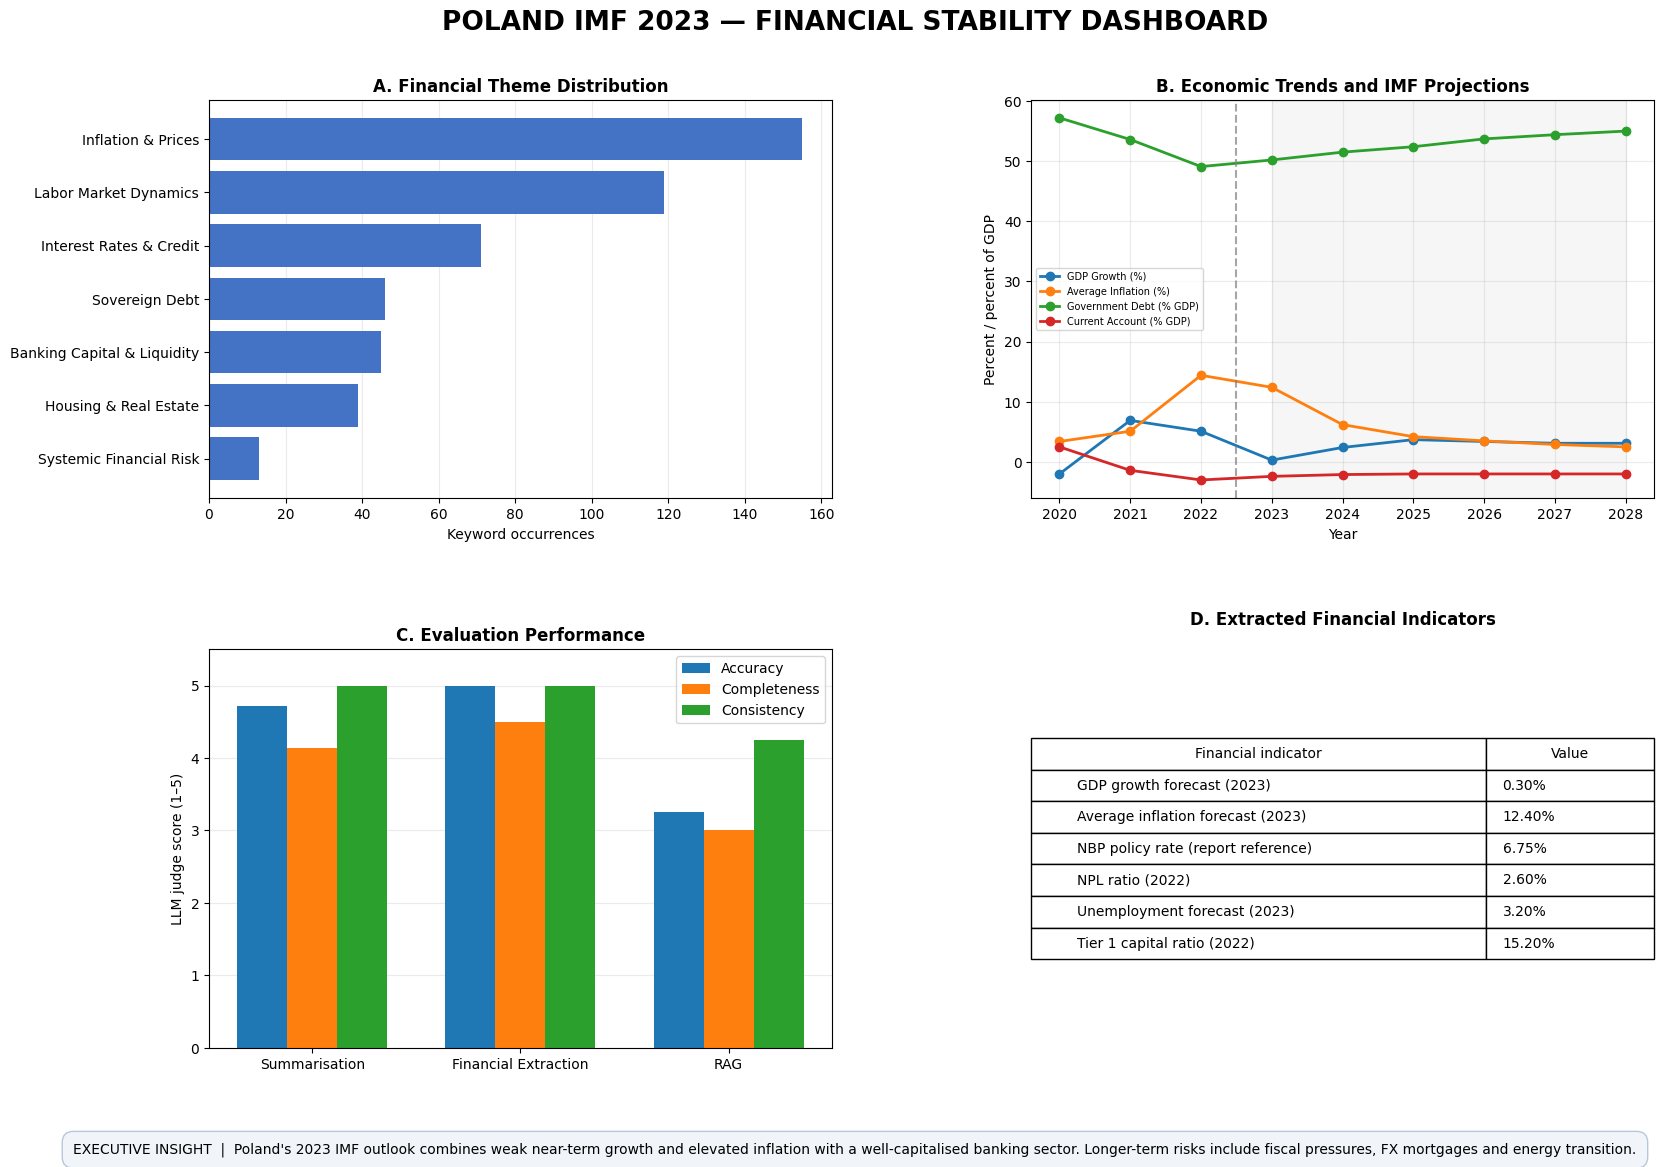

In [29]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json

# Load saved results
themes = pd.read_json(f"{OUTPUT_DIR}/financial_themes.json")
trends = pd.read_csv(f"{OUTPUT_DIR}/economic_trends.csv")

metrics = ["accuracy", "completeness", "consistency"]

evaluation_summary = pd.DataFrame({
    "category": ["Summarisation", "Financial Extraction", "RAG"],
    **{
        metric: [
            pd.to_numeric(
                summary_eval_df[metric], errors="coerce"
            ).mean(),
            pd.to_numeric(
                financial_eval_df[metric], errors="coerce"
            ).mean(),
            pd.to_numeric(
                pd.DataFrame(rag_evaluations)[metric],
                errors="coerce"
            ).mean()
        ]
        for metric in metrics
    }
})

# Four economic series in tidy format
trend_long = trends.melt(
    id_vars=["year", "period"],
    value_vars=[
        "GDP Growth (%)",
        "Average Inflation (%)",
        "Government Debt (% GDP)",
        "Current Account (% GDP)"
    ],
    var_name="indicator",
    value_name="value"
)

fig, axes = plt.subplots(2, 2, figsize=(17, 12))
fig.patch.set_facecolor("white")

# Panel 1 — Theme distribution
ax = axes[0, 0]
sorted_themes = themes.sort_values("count")
ax.barh(sorted_themes["theme"], sorted_themes["count"],
        color="#4472C4")
ax.set_title("A. Financial Theme Distribution", fontweight="bold")
ax.set_xlabel("Keyword occurrences")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

# Panel 2 — Economic trends
ax = axes[0, 1]
for indicator in trend_long["indicator"].unique():
    subset = trend_long[trend_long["indicator"] == indicator]
    ax.plot(subset["year"], subset["value"],
            marker="o", linewidth=2, label=indicator)

ax.axvline(2022.5, color="gray", linestyle="--", alpha=0.7)
ax.axvspan(2023, 2028, color="gray", alpha=0.07)
ax.set_title("B. Economic Trends and IMF Projections",
             fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Percent / percent of GDP")
ax.set_xticks(trends["year"])
ax.legend(fontsize=7, loc="best")
ax.grid(alpha=0.25)

# Panel 3 — Evaluation comparison
ax = axes[1, 0]
x = np.arange(len(evaluation_summary))
width = 0.24

for i, metric in enumerate(metrics):
    ax.bar(
        x + (i - 1) * width,
        evaluation_summary[metric],
        width,
        label=metric.title()
    )

ax.set_xticks(x)
ax.set_xticklabels(evaluation_summary["category"])
ax.set_ylim(0, 5.5)
ax.set_ylabel("LLM judge score (1–5)")
ax.set_title("C. Evaluation Performance", fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Panel 4 — Extracted financial indicators
ax = axes[1, 1]
ax.axis("off")

indicator_labels = {
    "gdp_growth_forecast_pct": "GDP growth forecast (2023)",
    "headline_inflation_rate_pct": "Average inflation forecast (2023)",
    "central_bank_policy_rate_pct": "NBP policy rate (report reference)",
    "non_performing_loan_ratio": "NPL ratio (2022)",
    "unemployment_rate_pct": "Unemployment forecast (2023)",
    "tier_1_capital_ratio": "Tier 1 capital ratio (2022)"
}

rows = [
    [
        indicator_labels[key],
        f"{financial_json[key]:.2f}%"
        if financial_json[key] is not None else "Not available"
    ]
    for key in indicator_labels
]

table = ax.table(
    cellText=rows,
    colLabels=["Financial indicator", "Value"],
    colWidths=[0.73, 0.27],
    loc="center",
    cellLoc="left"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2.0)

ax.set_title("D. Extracted Financial Indicators",
             fontweight="bold", pad=18)

# Executive insight overlay
insight = (
    "EXECUTIVE INSIGHT  |  Poland's 2023 IMF outlook combines weak near-term "
    "growth and elevated inflation with a well-capitalised banking sector. "
    "Longer-term risks include fiscal pressures, FX mortgages and energy transition."
)

fig.text(
    0.5, 0.035, insight,
    ha="center", va="center",
    fontsize=10, fontweight="medium",
    bbox=dict(facecolor="#F1F5FA",
              edgecolor="#B8C7DA", boxstyle="round,pad=0.8")
)

fig.suptitle(
    "POLAND IMF 2023 — FINANCIAL STABILITY DASHBOARD",
    fontsize=19, fontweight="bold", y=0.985
)

fig.subplots_adjust(
    left=0.12, right=0.97,
    top=0.91, bottom=0.12,
    hspace=0.38, wspace=0.32
)

dashboard_path = f"{OUTPUT_DIR}/poland_dashboard.png"
fig.savefig(dashboard_path, dpi=300, bbox_inches="tight")
plt.show()

Validation of Results

In [31]:

import os
import json
import pandas as pd
import faiss
from PIL import Image

required_files = [
    "pages.json",
    "chunks.json",
    "sections.json",
    "section_summaries.json",
    "executive_summary.json",
    "financial_themes.json",
    "financial_indicators.json",
    "financial_source_audit.json",
    "qualitative_insights.json",
    "economic_trends.json",
    "poland_faiss.index",
    "rag_metadata.json",
    "rag_answers.json",
    "rag_evaluations.json",
    "summary_evaluations.json",
    "financial_evaluations.json",
    "poland_dashboard.png"
]

checks = {}

checks["Required output files"] = all(
    os.path.exists(f"{OUTPUT_DIR}/{name}")
    for name in required_files
)

checks["PDF text extraction"] = len(pages) > 0
checks["Token-aware chunks"] = (
    len(chunks) > 0 and
    all(c["token_count"] <= 450 for c in chunks)
)

checks["Seven section summaries"] = len(summaries) == 7
checks["Summaries under 100 words"] = all(
    0 < s["word_count"] < 100
    for s in summaries.values()
)

checks["Executive summary"] = bool(
    executive_summary.strip()
)

indicator_keys = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

checks["Financial JSON schema"] = (
    financial_json.get("country_name") == "Poland"
    and all(k in financial_json for k in indicator_keys)
)

checks["Six numeric indicators"] = all(
    isinstance(financial_json[k], (int, float))
    and not isinstance(financial_json[k], bool)
    for k in indicator_keys
)

checks["Seven financial themes"] = len(theme_df) == 7

checks["Qualitative insights"] = (
    len(insights["strengths"]) == 6
    and len(insights["vulnerabilities"]) == 6
)

checks["Four economic trend series"] = (
    len(trend_long["indicator"].unique()) == 4
    and len(trend_long) == 36
    and trend_long["value"].notna().all()
)

checks["FAISS embedding index"] = (
    index.ntotal == len(chunks)
    and index.d == 768
)

checks["Four RAG answers"] = (
    len(rag_results) == 4
    and all(r["answer"].strip() for r in rag_results)
)

def scores_valid(records):
    return all(
        type(r.get(k)) is int and 1 <= r[k] <= 5
        for r in records
        for k in ["accuracy", "completeness", "consistency"]
    )

checks["RAG evaluations"] = (
    len(rag_evaluations) == 4
    and scores_valid(rag_evaluations)
)

checks["Summary evaluations"] = (
    len(summary_evaluations) == 7
    and scores_valid(summary_evaluations)
)

checks["Financial evaluations"] = (
    len(financial_evaluations) == 6
    and scores_valid(financial_evaluations)
)

image_path = f"{OUTPUT_DIR}/poland_dashboard.png"

if os.path.exists(image_path):
    with Image.open(image_path) as img:
        checks["High-resolution dashboard"] = (
            img.width >= 3000 and img.height >= 2000
        )
else:
    checks["High-resolution dashboard"] = False

print("FINAL POLAND PROJECT VALIDATION\n")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nFINAL RESULT")
print("Checks passed:", sum(checks.values()), "/", len(checks))
print("Status:", "PASS" if all(checks.values()) else "REVIEW REQUIRED")

FINAL POLAND PROJECT VALIDATION

Required output files: PASS
PDF text extraction: PASS
Token-aware chunks: PASS
Seven section summaries: PASS
Summaries under 100 words: PASS
Executive summary: PASS
Financial JSON schema: PASS
Six numeric indicators: PASS
Seven financial themes: PASS
Qualitative insights: PASS
Four economic trend series: PASS
FAISS embedding index: PASS
Four RAG answers: PASS
RAG evaluations: PASS
Summary evaluations: PASS
Financial evaluations: PASS
High-resolution dashboard: PASS

FINAL RESULT
Checks passed: 17 / 17
Status: PASS
